# Tiling pilot: exploration and QC

This notebook checks the tiles written by `data_prep/tile.py` for the six pilot slides in subset B,
before tiling the whole subset. It only reads files; nothing here changes the data.

**How to use:** run the Setup and Settings cells first, then any section. Run it in the `gbm-mgmt`
conda environment. The cells read `patches/index_B.csv`, each slide's `.h5` file and its `_qc.png`.

### Pilot slides

The six slides cover every scan resolution in the cohort, plus the two slides that exposed mask problems.

| Slide | Cohort | Scan | µm/px | Why it's in the pilot |
|---|---|---|---|---|
| TCGA-19-2625-01Z-00-DX1 | TCGA | 40× | 0.2520 | 40× scan; very pale stain |
| TCGA-12-0819-01Z-00-DX2 | TCGA | 20× | 0.4993 | Slide edge counted as tissue by the old mask |
| TCGA-06-0878-01Z-00-DX1 | TCGA | 20× | 0.5015 | Typical TCGA 20× scan |
| TCGA-14-0817-01Z-00-DX1 | TCGA | 20× | 0.5040 | Pale tissue missed by the old mask |
| C3N-01192-21 | CPTAC | 40× | 0.2523 | CPTAC's only 40× slide |
| C3N-02786-23 | CPTAC | 20× | 0.4942 | Typical CPTAC scan |

### Tiling config history

| Version | Grid and tile reads | Tissue mask |
|---|---|---|
| tiling-v1 | Custom grid in level-0 coordinates | TIAToolbox grayscale Otsu |
| tiling-v2 | TIAToolbox `SlidingWindowPatchExtractor` | TIAToolbox grayscale Otsu |
| tiling-v3 (current) | TIAToolbox `SlidingWindowPatchExtractor` | Saturation channel, lower cut of a three-class Otsu |

## Setup

All imports for the notebook, including `tile.py` and `download.py` from the repo's `data_prep/` folder
(set by `REPO`). Run this first. Importing TIAToolbox takes several seconds because it loads PyTorch.

In [14]:
import hashlib
import io
import sys
from pathlib import Path

import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tiatoolbox.wsicore.wsireader import WSIReader

# The repo's data_prep/ scripts, used by the "Before" cell.
REPO = Path("~/Bioinformatics/WSI/gbm-mgmt-wsi").expanduser()
sys.path.insert(0, str(REPO / "data_prep"))
import tile                                    # noqa: E402
from download import load_manifest, paths_for  # noqa: E402

### Settings

Used by the comparison cell (Tile scale and appearance).

- `ROOT`: the data folder that `download.py` and `tile.py` write to
- `SUBSET`: which `index_<SUBSET>.csv` to read
- `SLIDES`: slides to show, by slide ID or file-name prefix
- `GRID`: tiles per side of each tile grid (4 → 16 tiles)
- `SEED`: which random tiles are shown; the same seed shows the same tiles every run
- `SCALE_BAR_UM`: length of the scale bar drawn on each tile grid

The "Before" and "Checking every tile" cells set their own settings at the top, and they overwrite these
variables when run.

In [15]:
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
SLIDES = ["TCGA-19-2625-01Z-00-DX1", "TCGA-12-0819-01Z-00-DX2", "C3N-01192-21",
          "C3N-02786-23", "TCGA-14-0817-01Z-00-DX1"]
GRID = 4            # GRID x GRID tiles per slide
SEED = 0            # same seed -> same tiles every time the cell runs
SCALE_BAR_UM = 20

## Before the saturation mask (tiling-v2)

The tiling-v2 files were overwritten by the tiling-v3 run, so this cell rebuilds the tiles in memory instead
of reading them. It uses the current `tile.py` with `mask_method: otsu_gray`, which is the same mask, grid
and seeds as tiling-v2, so it reproduces the same 2,000 sampled tiles and the same 16 shown by the
comparison cell. Nothing is written. It needs the slide's `.svs` file under `ROOT/raw/` and imports
`tile.py` from the repo. `BEFORE_QC` is the copy of the tiling-v2 QC image saved before rerunning.

**Result:** the rebuild reports 8,617 tissue tiles for TCGA-12-0819, matching the tiling-v2 run, and the
blank beige tile (second row, first column) is back. It comes from the slide/coverslip edge, which the
grayscale mask outlined as tissue (the green line on the right of the QC image).

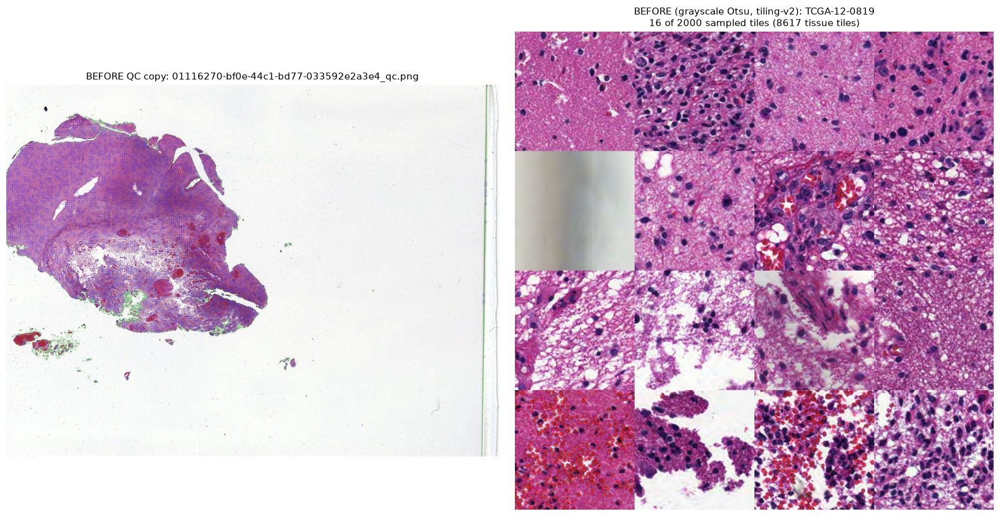

In [18]:
# BEFORE the saturation mask: rebuild the 16 random tiles the comparison cell showed under tiling-v2
# (grayscale Otsu), in memory without touching any files, next to the copied tiling-v2 QC image.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SLIDE = "TCGA-12-0819-01Z-00-DX2"   # slide ID or file-name prefix
BEFORE_QC = Path("~/Desktop/qc_otsu/01116270-bf0e-44c1-bd77-033592e2a3e4_qc.png").expanduser()
GRID = 4
SEED = 0                            # same SEED as the comparison cell -> same 16 tiles

# tiling-v2 = current settings with the grayscale Otsu mask.
cfg = {**tile.load_config(REPO / "configs" / "tiling.yaml")[0], "mask_method": "otsu_gray"}
_, manifest = load_manifest(tile.DEFAULT_MANIFEST)
row = next(r for r in manifest["files"] if r["slide_id"] == SLIDE or r["file_name"].startswith(SLIDE))

wsi = WSIReader.open(paths_for(ROOT, row)[0])
_, _, _, extractor = tile.tissue_grid(wsi, cfg)
n_tissue = len(extractor.coordinate_list)

# Same sampling as tile.py's tile_slide, then the same 16-tile pick as the comparison cell.
seed = int.from_bytes(hashlib.sha256(f"{cfg['seed']}|{row['slide_id']}".encode()).digest()[:8], "big")
count = min(n_tissue, cfg["max_tiles_per_slide"])
chosen = np.sort(np.random.default_rng(seed).choice(n_tissue, size=count, replace=False))
shown = sorted(np.random.default_rng(SEED).choice(count, size=min(GRID * GRID, count), replace=False))
tiles = [extractor[int(chosen[i])][..., :3] for i in shown]

px = cfg["tile_px"]
grid = np.full((GRID * px, GRID * px, 3), 255, dtype=np.uint8)
for k, t in enumerate(tiles):
    r, c = divmod(k, GRID)
    grid[r * px:(r + 1) * px, c * px:(c + 1) * px] = t

fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 8))
if BEFORE_QC.exists():
    ax_qc.imshow(Image.open(BEFORE_QC))
    ax_qc.set_title(f"BEFORE QC copy: {BEFORE_QC.name}", fontsize=11)
ax_qc.axis("off")
ax_tiles.imshow(grid)
ax_tiles.set_title(f"BEFORE (grayscale Otsu, tiling-v2): {row['patient_id']}\n"
                   f"16 of {count} sampled tiles ({n_tissue} tissue tiles)", fontsize=11)
ax_tiles.axis("off")
plt.tight_layout()
plt.show()

## Tile scale and appearance (current config)

For each slide in `SLIDES`: the QC overview (tissue outline in green, sampled tiles in blue) next to 16
random tiles, with a 20 µm scale bar on the bottom-left tile.

**What to check**

- **Scale:** nuclei and red blood cells (about 7 µm) should be the same size relative to the bar in the
  40× and 20× rows. That confirms the resampling to 0.5 µm/px.
- **Coverage:** the blue tiles should sit on tissue, not on glass, the slide edge or pen marks.

**Results (tiling-v3)**

- Scale is consistent across 40× and 20× slides and across both cohorts.
- TCGA-14-0817: tissue tiles went from 2,408 to 3,122; the pale band at the top and most of the pale
  top-left section are now tiled.
- TCGA-12-0819: the slide-edge strip is no longer outlined or tiled (8,617 → 8,557 tissue tiles).
- TCGA-19-2625 (all pale): fully captured (5,885 → 6,061); faint dust specks are outlined but not tiled.
- CPTAC slides: essentially unchanged (C3N-01192-21: 1,724 → 1,769; C3N-02786-23: 864 → 913).

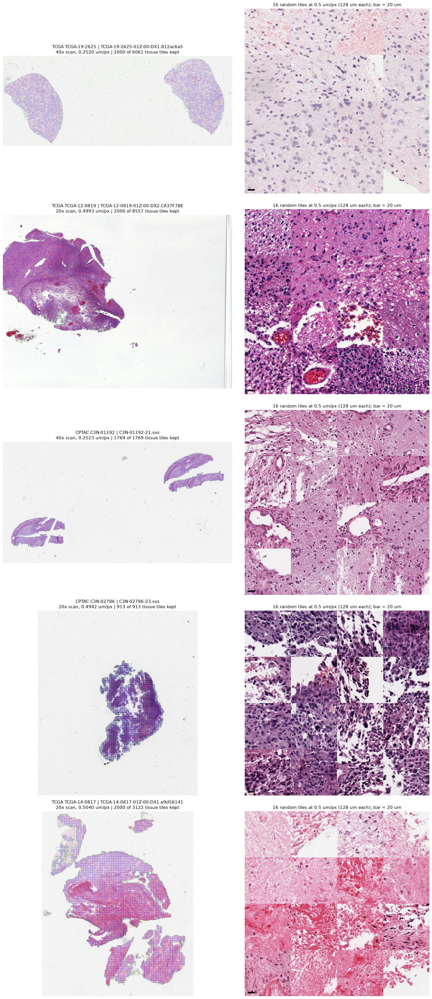

In [16]:
# Compare tiled slides: QC overview (tissue outline + sampled tiles) next to a grid of random tiles.
# Each tile grid has a 20 um scale bar, so nucleus size can be compared across slides and scanners.
index = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
rows = []
for key in SLIDES:
    match = index[(index.slide_id == key) | index.file_name.str.startswith(key)]
    if len(match) != 1:
        raise ValueError(f"{key}: {len(match)} matching slides in index_{SUBSET}.csv")
    rows.append(match.iloc[0])

fig, axes = plt.subplots(len(rows), 2, figsize=(16, 7 * len(rows)),
                         gridspec_kw={"width_ratios": [1, 1]}, squeeze=False)
for (ax_qc, ax_tiles), row in zip(axes, rows):
    h5_path = ROOT / row.h5
    qc = Image.open(h5_path.with_name(h5_path.stem + "_qc.png"))
    with h5py.File(h5_path) as h5:
        attrs = dict(h5.attrs)
        n = len(h5["tiles"])
        chosen = np.random.default_rng(SEED).choice(n, size=min(GRID * GRID, n), replace=False)
        tiles = [np.asarray(Image.open(io.BytesIO(h5["tiles"][i].tobytes()))) for i in sorted(chosen)]

    tile_px = int(attrs["tile_px"])
    grid = np.full((GRID * tile_px, GRID * tile_px, 3), 255, dtype=np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, GRID)
        grid[r * tile_px:(r + 1) * tile_px, c * tile_px:(c + 1) * tile_px] = img
    bar_px = int(round(SCALE_BAR_UM / attrs["target_mpp"]))
    grid[-24:-16, 16:16 + bar_px] = 0   # black bar in the bottom-left tile

    scan = "40x" if attrs["source_mpp_x"] < 0.35 else "20x"
    ax_qc.imshow(qc)
    ax_qc.set_title(f"{row.source} {row.patient_id} | {row.file_name[:32]}\n"
                    f"{scan} scan, {attrs['source_mpp_x']:.4f} um/px | "
                    f"{attrs['n_sampled']} of {attrs['n_tissue_tiles']} tissue tiles kept", fontsize=11)
    ax_tiles.imshow(grid)
    ax_tiles.set_title(f"{len(tiles)} random tiles at {attrs['target_mpp']} um/px "
                       f"({attrs['tile_um']:.0f} um each); bar = {SCALE_BAR_UM} um", fontsize=11)
    for ax in (ax_qc, ax_tiles):
        ax.axis("off")
plt.tight_layout()
plt.show()

## Checking every tile

Scores every sampled tile on four measures, then shows, per slide, a contact sheet of all its tiles
(flagged tiles boxed in red, in grid order so neighbouring tiles form continuous tissue) and the 8 worst
tiles for each measure. A summary table of flag counts per slide comes last.

| Measure | Definition | Flag when | Catches |
|---|---|---|---|
| glass | fraction of near-white, uncolored pixels | > 0.5 | background, tissue edges |
| dark | fraction of very dark pixels (V < 60) | > 0.2 | folds, debris, ink |
| green | fraction of green pixels | > 0.02 | green marker ink |
| blur | variance of the Laplacian | < 50 | out-of-focus or featureless tiles |

Flags mark tiles to look at, not tiles to drop. Set `SHOW_FIGURES = False` to get only the summary table,
for example across all of subset B after the full run, then turn figures on for the slides with the most
flags.

**Results (tiling-v3, about 10,700 tiles)**

| Slide | Flagged | What's really there |
|---|---|---|
| TCGA-12-0819 | 7 | One real artifact: a dark debris clump (dark 0.56, blur 16). The rest are tissue-edge tiles. |
| TCGA-14-0817 | 50 | Edge and fragmented tissue at 59–64% glass. One smeared tile (blur 164), not flagged. |
| TCGA-19-2625 | 1,805 | Mostly false alarms (see below); the worst is real: a blank background smudge (glass 1.00, blur 3). |
| TCGA-06-0878 | 40 | Tissue-edge tiles. |
| C3N-01192-21 | 55 | Tissue-edge tiles. |
| C3N-02786-23 | 38 | Tissue-edge tiles. |

Genuinely bad tiles are rare: about 3 of ~10,700 (under 0.1%).

**Open issue:** the glass rule (saturation < 20 and V > 200) counts pale tissue as glass. TCGA-19-2625's
tissue sits at saturation 13–20, so 1,805 of its 2,000 tissue tiles are flagged. Background on every pilot
slide sits at 0–3, so `(s < 8) & (v > 200)` in `tile_measures` should fix it (not yet changed).

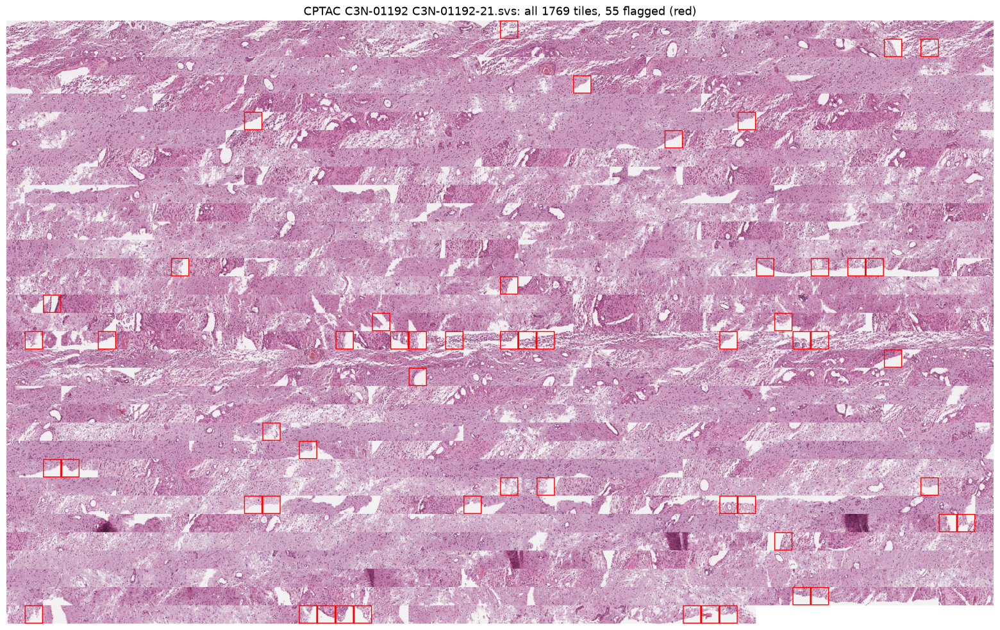

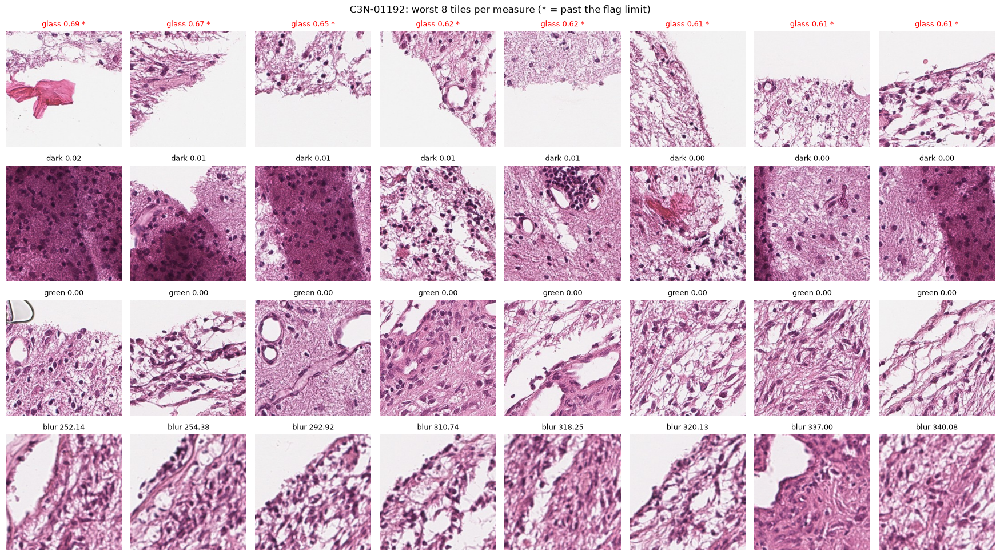

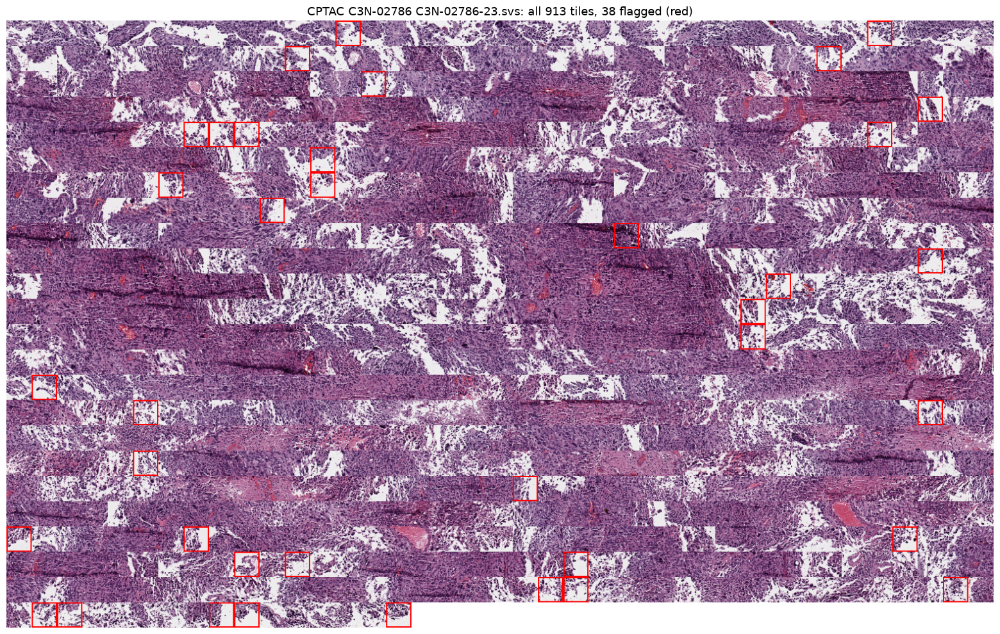

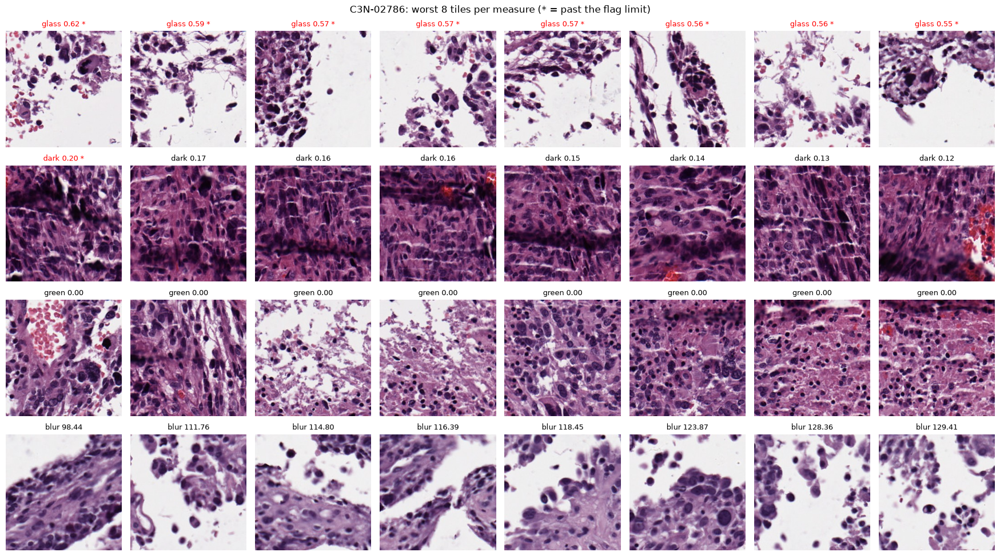

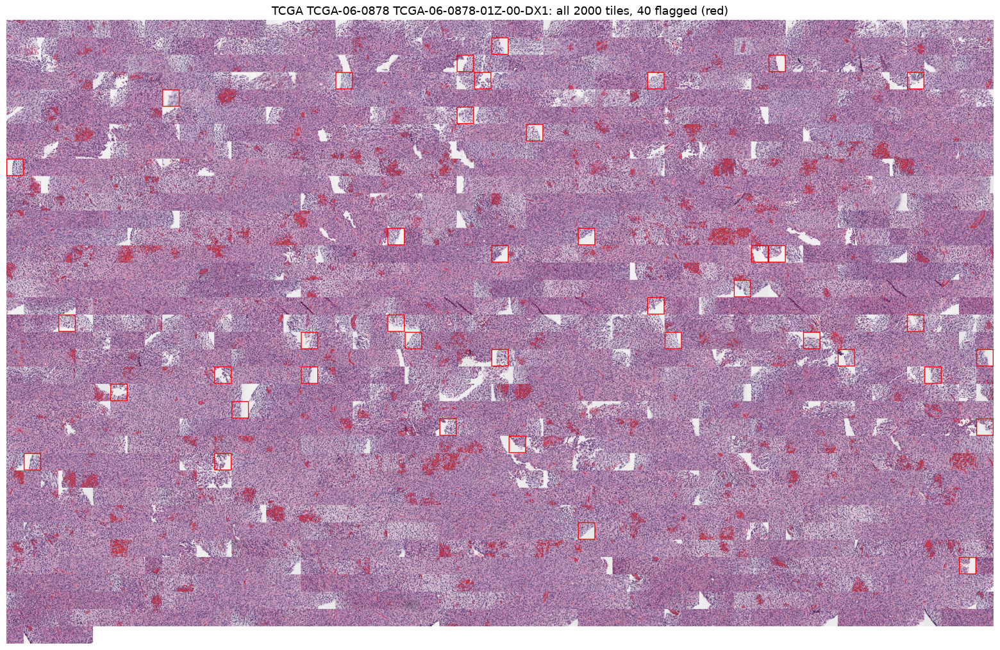

...

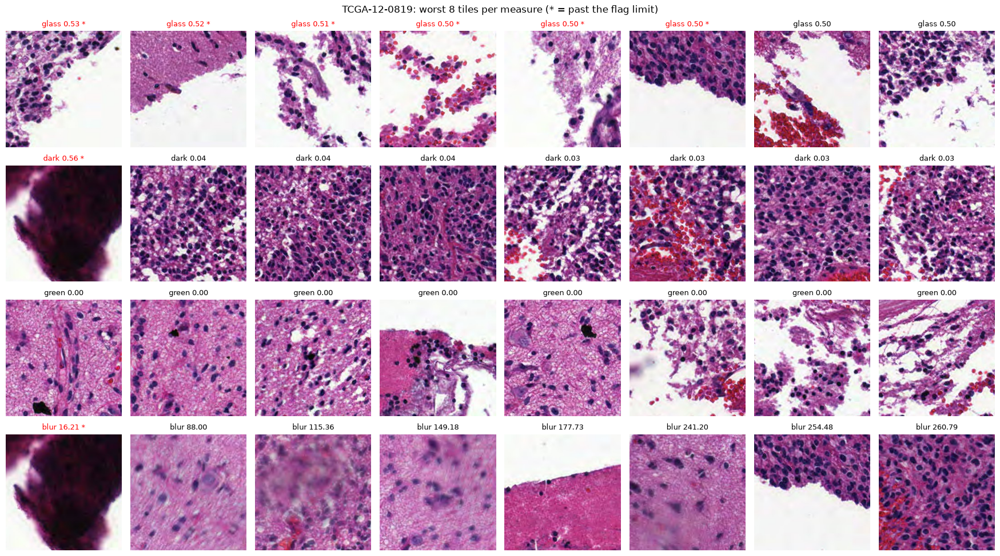

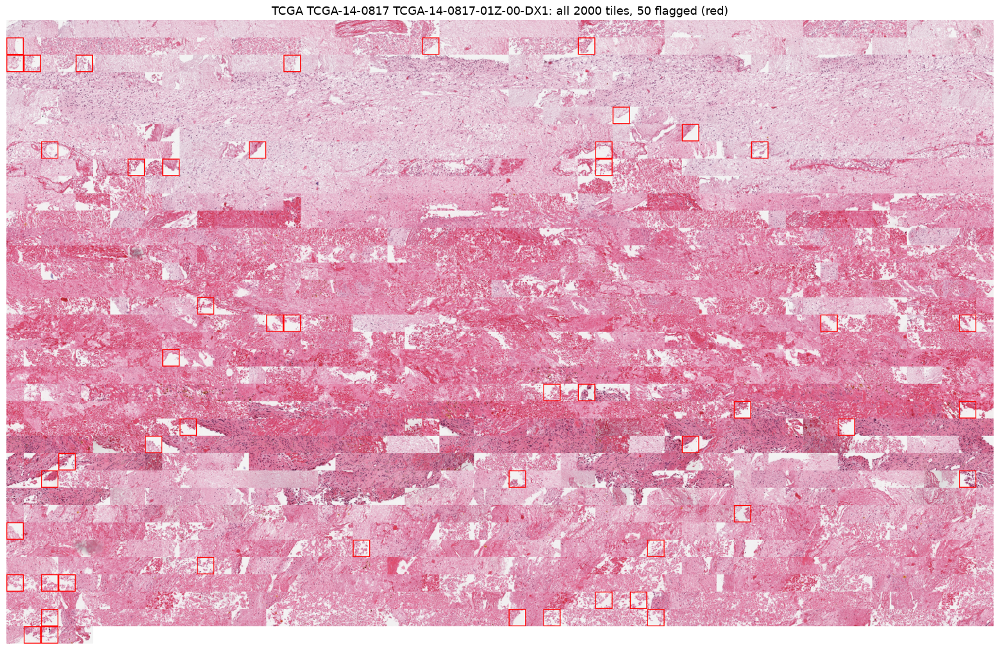

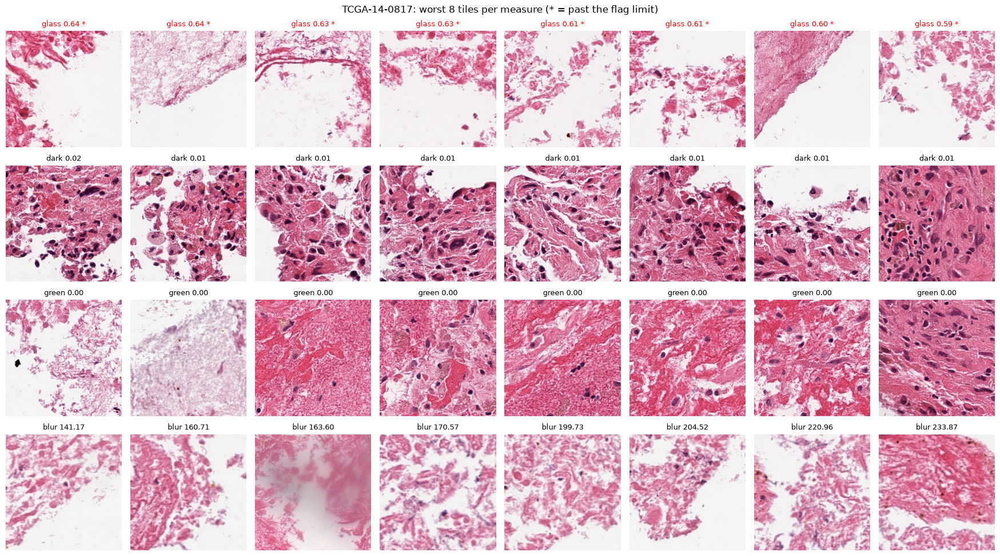

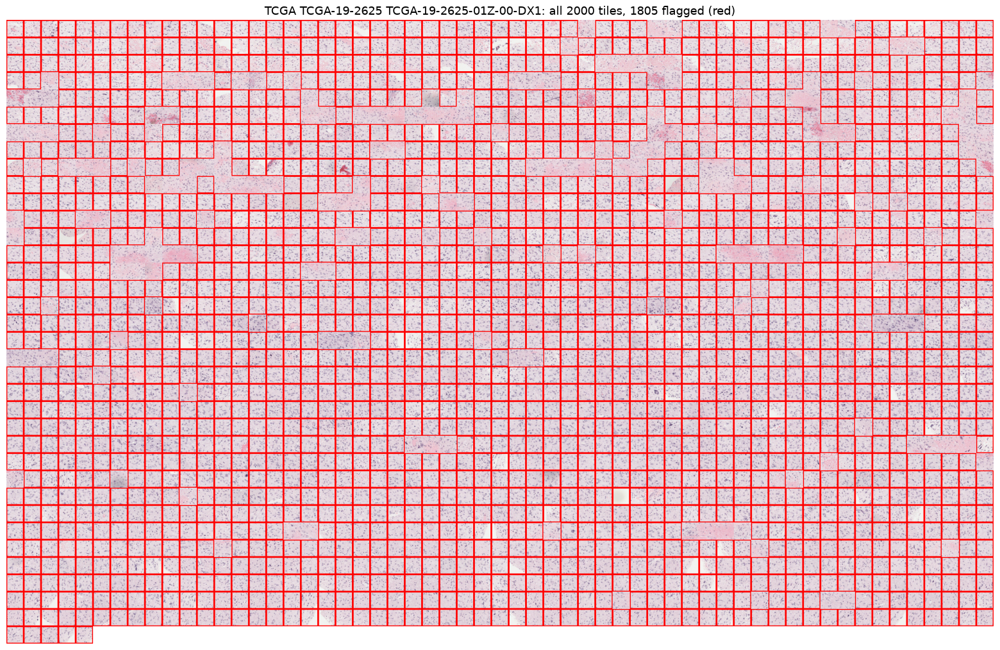

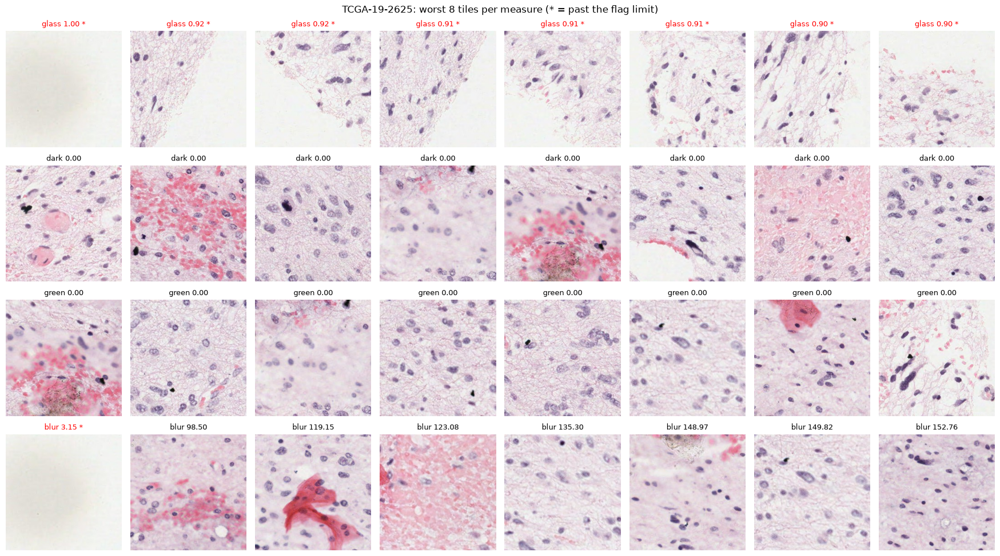

,patient,file,tiles,glass_flagged,dark_flagged,green_flagged,blur_flagged,any_flag,median_blur
0,C3N-01192,C3N-01192-21.svs,1769,55,0,0,0,55,5141
1,C3N-02786,C3N-02786-23.svs,913,37,1,0,0,38,466
2,TCGA-06-0878,TCGA-06-0878-01Z-00-DX1,2000,39,0,0,1,40,499
3,TCGA-12-0819,TCGA-12-0819-01Z-00-DX2,2000,6,1,0,1,7,911
4,TCGA-14-0817,TCGA-14-0817-01Z-00-DX1,2000,50,0,0,0,50,1291
5,TCGA-19-2625,TCGA-19-2625-01Z-00-DX1,2000,1805,0,0,1,1805,621


In [17]:
# Check every tile of the tiled slides: per-tile quality measures, a flagged-tile summary,
# a contact sheet of ALL tiles per slide (flagged tiles boxed in red), and the worst tiles per measure.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
SLIDES = None        # None = every slide in index_<SUBSET>.csv; or a list of slide IDs / file-name prefixes
THUMB_PX = 40        # size of each tile in the contact sheet
WORST_N = 8          # full-size examples shown per measure
SHOW_FIGURES = True  # False = summary table only (for checking many slides at once)
FLAGS = {            # measure: (rule, limit) -- a tile is flagged when the rule holds
    "glass":  (">", 0.5),    # fraction of near-white, uncolored pixels (background)
    "dark":   (">", 0.2),    # fraction of very dark pixels (folds, debris, ink)
    "green":  (">", 0.02),   # fraction of green pixels (green marker ink)
    "blur":   ("<", 50.0),   # variance of the Laplacian; low = out of focus or featureless
}


def tile_measures(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return {"glass": float(((s < 20) & (v > 200)).mean()),
            "dark": float((v < 60).mean()),
            "green": float(((h >= 35) & (h <= 85) & (s > 60)).mean()),
            "blur": float(cv2.Laplacian(gray, cv2.CV_64F).var())}


def flagged(row):
    return [m for m, (rule, limit) in FLAGS.items()
            if (row[m] > limit if rule == ">" else row[m] < limit)]


index = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
if SLIDES is not None:
    index = index[index.slide_id.isin(SLIDES) | index.file_name.str.startswith(tuple(SLIDES))]

summary = []
for slide in index.itertuples():
    with h5py.File(ROOT / slide.h5) as h5:
        tiles = [np.asarray(Image.open(io.BytesIO(t.tobytes()))) for t in h5["tiles"][:]]
    stats = pd.DataFrame([tile_measures(t) for t in tiles])
    stats["flagged_by"] = stats.apply(flagged, axis=1)
    bad = stats["flagged_by"].str.len() > 0
    summary.append({"patient": slide.patient_id, "file": slide.file_name[:23], "tiles": len(tiles),
                    **{f"{m}_flagged": int(stats["flagged_by"].apply(lambda f: m in f).sum()) for m in FLAGS},
                    "any_flag": int(bad.sum()), "median_blur": round(stats.blur.median())})

    if not SHOW_FIGURES:
        continue

    # Contact sheet of every tile, flagged ones outlined in red.
    cols = int(np.ceil(np.sqrt(len(tiles) * 1.6)))
    rows = int(np.ceil(len(tiles) / cols))
    sheet = np.full((rows * THUMB_PX, cols * THUMB_PX, 3), 255, np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, cols)
        small = cv2.resize(img, (THUMB_PX, THUMB_PX), interpolation=cv2.INTER_AREA)
        if bad[k]:
            cv2.rectangle(small, (0, 0), (THUMB_PX - 1, THUMB_PX - 1), (255, 0, 0), 2)
        sheet[r * THUMB_PX:(r + 1) * THUMB_PX, c * THUMB_PX:(c + 1) * THUMB_PX] = small
    plt.figure(figsize=(20, 20 * rows / cols))
    plt.imshow(sheet)
    plt.title(f"{slide.source} {slide.patient_id} {slide.file_name[:23]}: all {len(tiles)} tiles, "
              f"{int(bad.sum())} flagged (red)", fontsize=13)
    plt.axis("off")
    plt.show()

    # The worst tiles for each measure, full size, with their values.
    fig, axes = plt.subplots(len(FLAGS), WORST_N, figsize=(2.2 * WORST_N, 2.5 * len(FLAGS)), squeeze=False)
    for ax_row, (m, (rule, limit)) in zip(axes, FLAGS.items()):
        order = stats[m].sort_values(ascending=(rule == "<")).index[:WORST_N]
        for ax, k in zip(ax_row, order):
            ax.imshow(tiles[k])
            ax.set_title(f"{m} {stats.at[k, m]:.2f}" + (" *" if m in stats.at[k, "flagged_by"] else ""),
                         fontsize=9, color="red" if m in stats.at[k, "flagged_by"] else "black")
            ax.axis("off")
    fig.suptitle(f"{slide.patient_id}: worst {WORST_N} tiles per measure (* = past the flag limit)", fontsize=12)
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(summary))

## Next steps

- Fix the glass rule in the "Checking every tile" cell.
- Decide whether `tile.py` should drop essentially empty or featureless tiles at extraction (for example
  blur < 20 or glass > 0.9 with the corrected rule). In this pilot that would remove only the blank smudge
  and the debris clump.
- Commit, then tile all of subset B; Carlos tiles subset A from the same commit.